Experiment: Density-Based Clustering (DBSCAN)

Aim: To apply DBSCAN clustering and compare the results with K-Means on a noisy dataset.

First we import the required libraries.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import adjusted_rand_score

Now we create a dataset. We take the moons dataset and add some random points to act as noise.

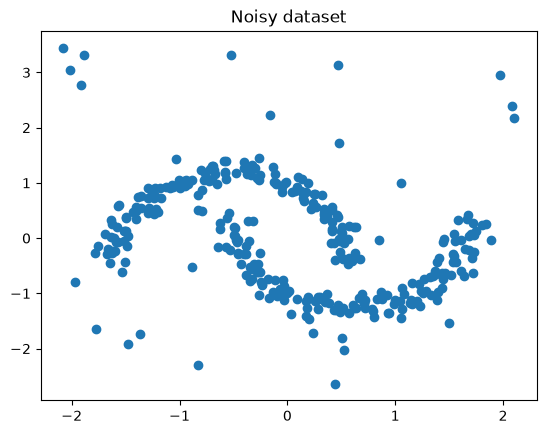

In [2]:
np.random.seed(42)

X, y = make_moons(n_samples=300, noise=0.07, random_state=42)
noise = np.random.uniform(-1.5, 2.5, size=(30, 2))

X = np.vstack([X, noise])
y = np.concatenate([y, -np.ones(30, dtype=int)])

X = StandardScaler().fit_transform(X)

plt.scatter(X[:, 0], X[:, 1])
plt.title("Noisy dataset")
plt.show()

Applying K-Means with 2 clusters.

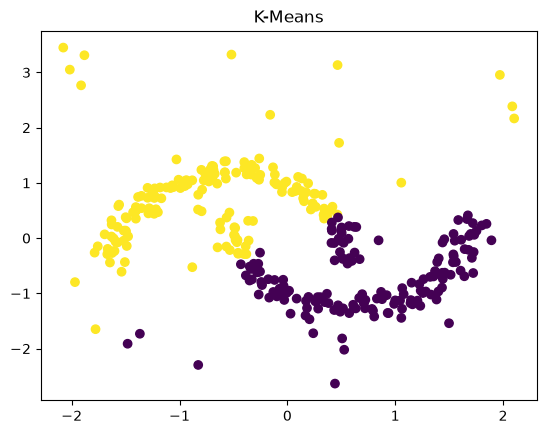

In [3]:
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
km_labels = kmeans.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=km_labels)
plt.title("K-Means")
plt.show()

Applying DBSCAN. Points labelled -1 are noise.

Clusters found: 2
Noise points: 22


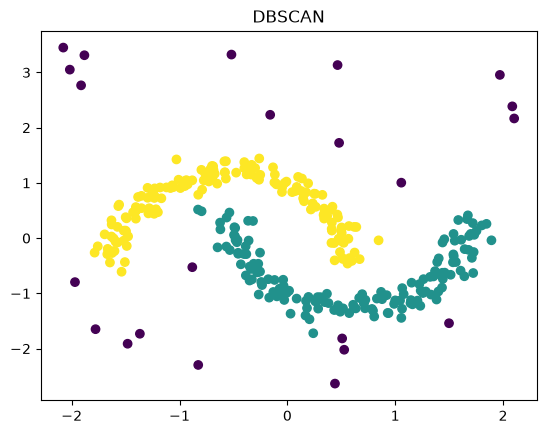

In [4]:
dbscan = DBSCAN(eps=0.3, min_samples=5)
db_labels = dbscan.fit_predict(X)

print("Clusters found:", len(set(db_labels)) - (1 if -1 in db_labels else 0))
print("Noise points:", list(db_labels).count(-1))

plt.scatter(X[:, 0], X[:, 1], c=db_labels)
plt.title("DBSCAN")
plt.show()

To compare, we use the adjusted rand index. It is 1 when the clustering matches the true labels. Here we check only the original moon points, not the added noise.

In [5]:
real = y != -1

print("K-Means ARI:", adjusted_rand_score(y[real], km_labels[real]))
print("DBSCAN ARI:", adjusted_rand_score(y[real], db_labels[real]))

K-Means ARI: 0.46973837022440984
DBSCAN ARI: 1.0


Conclusion: K-Means splits the data with a straight line and puts the noise points into clusters. DBSCAN follows the shape of the moons and marks the noise points separately, so it works better on noisy data. DBSCAN depends on the eps value, so it has to be chosen carefully.